In [1]:
# =============================================================================
# CELL 0 | LIBRARY IMPORTS
# PURPOSE : Load all Python libraries required for the entire notebook.
# WHY     : Centralising imports here avoids repeated imports in every cell
#           and makes dependency management clean and explicit.
# LIBRARIES:
#   pandas / numpy     - tabular data manipulation and numerical operations
#   matplotlib / seaborn - static plotting and EDA visualisations
#   sklearn            - preprocessing, ML models, and evaluation metrics
#   warnings           - suppress noisy convergence warnings during training
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

# Time-series aware cross-validation and multi-metric scorer
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Pipeline construction and preprocessing transformers
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Regression models - spanning linear, tree, ensemble, kernel, and neural methods
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from sklearn.svm import SVR, SVC  # SVR for regression, SVC for classification
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

# Standard regression evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")  # Suppress sklearn convergence / deprecation warnings

sns.set_theme(style="whitegrid")   # Clean white-grid background for all seaborn plots

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# =============================================================================
# CELL 1 | DATA LOADING
# PURPOSE : Read the India Rainfall & Crop Yield CSV dataset into a DataFrame.
# WHY     : We strip column-name whitespace immediately after loading to prevent
#           KeyError mismatches caused by invisible leading/trailing spaces.
# DATASET : india_rainfall_crop_yield_2014_2024.csv
#   Rows  : 7,920 agricultural records (state × crop × year × season)
#   Period: 2014 – 2024 (11 years of Indian agronomic data)
# =============================================================================

import pandas as pd

file_path = 'india_rainfall_crop_yield_2014_2024 (1).csv'

try:
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()  # Remove leading/trailing whitespace from column names
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)    # Expected: (7920, N)
    display(df.head())                   # Preview first 5 rows
except FileNotFoundError:
    print(f"File not found at {file_path}. Please check your file system.")


Dataset loaded successfully!
Dataset shape: (7920, 17)


,Record_ID,State,District,Year,Season,Crop_Type,Rainfall_mm,Avg_Temperature_C,Humidity_percent,Soil_Type,Irrigation_Type,Fertilizer_Used_kg,Pesticide_Used_kg,Cultivated_Area_hectares,Yield_ton_per_hectare,Market_Price_per_ton,Farmer_Profit_INR
0,1,Uttarakhand,Dehradun,2014,Kharif,Rice,445.02,23.5,47.3,Black,Sprinkler,344.59,42.22,4471.68,1.83,34361.86,67904.0
1,2,Uttarakhand,Dehradun,2014,Rabi,Wheat,1410.24,32.3,73.6,Red,Rain-fed,217.81,29.71,1463.13,7.55,52216.79,106010.0
2,3,Uttarakhand,Dehradun,2014,Kharif,Maize,787.56,33.3,40.6,Laterite,Canal,201.97,24.74,1785.38,3.13,14302.87,70380.0
3,4,Uttarakhand,Dehradun,2014,Kharif,Cotton,1892.93,30.4,82.4,Alluvial,Tube Well,280.94,43.75,324.54,2.86,27337.56,8166.0
4,5,Uttarakhand,Dehradun,2014,Zaid,Cotton,1216.14,34.7,43.9,Black,Drip,192.11,41.86,3538.92,6.19,15784.33,314345.0


In [3]:
# =============================================================================
# CELL 2 | EXPLORATORY DATA ANALYSIS (EDA) - BASIC SUMMARY
# PURPOSE : Understand the structural properties of the dataset:
#           row/column counts, data types, missing values, duplicates, and
#           descriptive statistics for all numeric columns.
# WHY     : Detecting missing values early avoids silent errors in model training.
#           Duplicate records can bias model evaluation metrics if not removed.
# =============================================================================

print("Dataset Information")
print("--------------------")

print("Rows:", df.shape[0])       # Total number of records
print("Columns:", df.shape[1])    # Total number of features (including target)

print("\nColumn Names:")
print(df.columns.tolist())         # Full list of feature names

print("\nData Types:")
display(df.dtypes)                 # Identify numeric vs object columns

print("\nMissing Values:")          # Count NaN per column; imputation strategy depends on this
display(df.isnull().sum())

print("\nDuplicate Records:")       # Duplicate rows would inflate training data artificially
print(df.duplicated().sum())

print("\nDescriptive Statistics:")
display(df.describe().T)           # Mean, std, min, max, quartiles for all numeric columns


Dataset Information
--------------------
Rows: 7920
Columns: 17

Column Names:
['Record_ID', 'State', 'District', 'Year', 'Season', 'Crop_Type', 'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_percent', 'Soil_Type', 'Irrigation_Type', 'Fertilizer_Used_kg', 'Pesticide_Used_kg', 'Cultivated_Area_hectares', 'Yield_ton_per_hectare', 'Market_Price_per_ton', 'Farmer_Profit_INR']

Data Types:


Record_ID                     int64
State                        object
District                     object
Year                          int64
Season                       object
Crop_Type                    object
Rainfall_mm                 float64
Avg_Temperature_C           float64
Humidity_percent            float64
Soil_Type                    object
Irrigation_Type              object
Fertilizer_Used_kg          float64
Pesticide_Used_kg           float64
Cultivated_Area_hectares    float64
Yield_ton_per_hectare       float64
Market_Price_per_ton        float64
Farmer_Profit_INR           float64
dtype: object


Missing Values:


Record_ID                   0
State                       0
District                    0
Year                        0
Season                      0
Crop_Type                   0
Rainfall_mm                 0
Avg_Temperature_C           0
Humidity_percent            0
Soil_Type                   0
Irrigation_Type             0
Fertilizer_Used_kg          0
Pesticide_Used_kg           0
Cultivated_Area_hectares    0
Yield_ton_per_hectare       0
Market_Price_per_ton        0
Farmer_Profit_INR           0
dtype: int64


Duplicate Records:
0

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Record_ID,7920.0,3960.500000,2286.451399,1.00,1980.7500,3960.500,5940.2500,7920.00
Year,7920.0,2019.000000,3.162477,2014.00,2016.0000,2019.000,2022.0000,2024.00
Rainfall_mm,7920.0,1303.157420,516.667333,400.80,855.2800,1305.420,1752.0575,2199.58
Avg_Temperature_C,7920.0,28.070985,5.806386,18.00,23.0000,28.100,33.2000,38.00
Humidity_percent,7920.0,62.466869,15.817427,35.00,49.0000,62.700,76.0000,90.00
Fertilizer_Used_kg,7920.0,250.312962,114.850492,50.17,149.9575,251.350,350.6925,449.90
Pesticide_Used_kg,7920.0,32.569508,15.916997,5.00,18.6500,32.860,46.3025,59.98
Cultivated_Area_hectares,7920.0,2563.768706,1414.030920,100.65,1331.8425,2567.445,3796.0150,4999.30
Yield_ton_per_hectare,7920.0,4.832213,2.127995,1.20,2.9500,4.850,6.6800,8.50
Market_Price_per_ton,7920.0,38279.748221,15273.022319,12014.35,25045.9675,38261.045,51779.0575,64998.76


In [4]:
# =============================================================================
# CELL 3 | FEATURE & TARGET DEFINITION
# PURPOSE : Declare the target variable (Crop Yield) and separate features into
#           categorical and numerical groups for downstream preprocessing.
# WHY     : Separating feature types is required by ColumnTransformer, which
#           applies different transformations to each type:
#           - Categorical → OneHotEncoding (converts text to binary indicator columns)
#           - Numerical   → Median Imputation + StandardScaling (zero mean, unit variance)
# NOTE    : Rows with missing target or Year values are dropped to ensure
#           valid temporal train/test splits.
# =============================================================================

target = "Yield_ton_per_hectare"   # Task 1 target: crop yield prediction (tons/hectare)

# Categorical features - require encoding before ML models can process them
categorical_features = [
    "State",
    "Season",
    "Crop_Type",
    "Soil_Type",
    "Irrigation_Type"
]

# Numerical features - continuous agronomic and weather measurements
numeric_features = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_percent",
    "Fertilizer_Used_kg",
    "Pesticide_Used_kg",
    "Cultivated_Area_hectares"
]

features = categorical_features + numeric_features  # Combined feature list

# Remove rows with missing target values
data = df.dropna(subset=[target, "Year"]).copy()

X = data[features].copy()
y = pd.to_numeric(data[target], errors="coerce")  # Ensure target is numeric

# Convert numeric columns into numeric format (handles string-encoded numbers)
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

valid = y.notna()  # Keep only rows where target is a valid number

X = X.loc[valid]
y = y.loc[valid]
data = data.loc[valid]

print("Input shape:", X.shape)   # (n_valid_rows, n_features)
print("Target shape:", y.shape)

print("\nTarget Variable:")
print(target)

print("\nTarget Statistics:")
display(y.describe())            # Min/max/mean of crop yield distribution


Input shape: (7920, 11)
Target shape: (7920,)

Target Variable:
Yield_ton_per_hectare

Target Statistics:


count    7920.000000
mean        4.832213
std         2.127995
min         1.200000
25%         2.950000
50%         4.850000
75%         6.680000
max         8.500000
Name: Yield_ton_per_hectare, dtype: float64

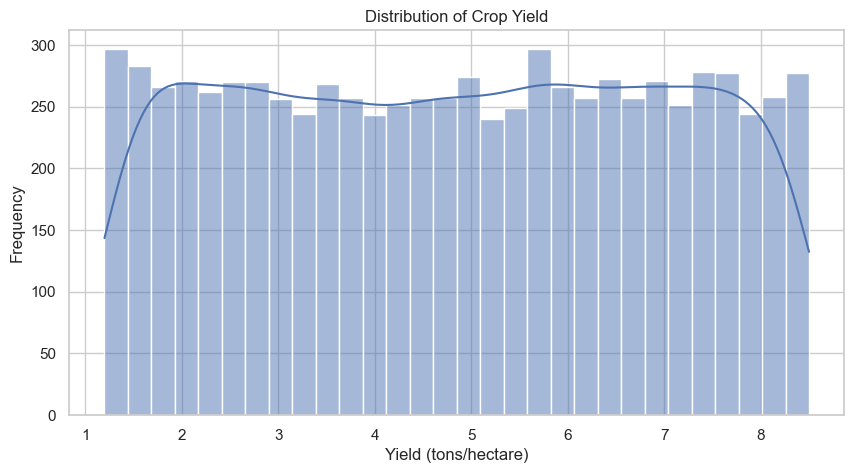

Skewness: -0.006040861016935411
Mean: 4.8322133838383845
Standard Deviation: 2.127994671232924
Minimum: 1.2
Maximum: 8.5


In [5]:
# =============================================================================
# CELL 4 | TARGET DISTRIBUTION - CROP YIELD HISTOGRAM
# PURPOSE : Visualise the distribution of crop yield across all records.
# WHY     : Understanding the target distribution helps us:
#           1. Detect skewness → consider log-transformation if heavily skewed
#           2. Identify outliers → extreme values may require capping/winsorising
#           3. Confirm normality assumptions for linear models (Ridge, Lasso)
# KDE LINE: The kernel density estimate overlaid on the histogram shows the
#           smooth probability density, making skewness visually apparent.
# =============================================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    y,
    kde=True,     # Overlay kernel density estimate (KDE) curve
    bins=30
)

plt.title("Distribution of Crop Yield")
plt.xlabel("Yield (tons/hectare)")
plt.ylabel("Frequency")
plt.show()

# Statistical summary of the yield distribution
print("Skewness:", y.skew())           # 0 = symmetric; >0 = right-skewed; <0 = left-skewed
print("Mean:", y.mean())               # Average yield across all records
print("Standard Deviation:", y.std())  # Spread of yield values
print("Minimum:", y.min())             # Lowest observed yield
print("Maximum:", y.max())             # Highest observed yield


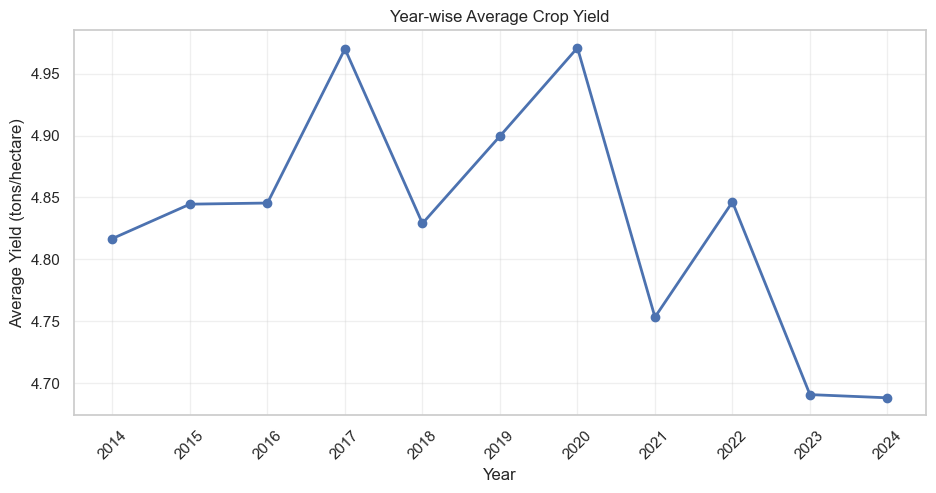

Year
2014    4.816736
2015    4.844528
2016    4.845444
2017    4.970069
2018    4.828958
2019    4.899528
2020    4.970903
2021    4.753222
2022    4.846333
2023    4.690611
2024    4.688014
Name: Yield_ton_per_hectare, dtype: float64

In [6]:
# =============================================================================
# CELL 5 | YEARLY YIELD TREND (2014–2024)
# PURPOSE : Plot the average crop yield per year to detect temporal trends.
# WHY     : Agricultural yield typically follows temporal patterns driven by
#           climate change, technology adoption, and policy interventions.
#           A trend line informs whether time-based modelling is warranted.
# INSIGHT : Rising trend confirms improving agronomic practices; a decline
#           would signal systemic stress (drought, pest outbreaks, etc.).
# =============================================================================

yearly_yield = data.groupby("Year")[target].mean()  # Average yield grouped by calendar year

plt.figure(figsize=(11, 5))

plt.plot(
    yearly_yield.index,
    yearly_yield.values,
    marker="o",         # Circular markers at each year point
    linewidth=2
)

plt.title("Year-wise Average Crop Yield")
plt.xlabel("Year")
plt.ylabel("Average Yield (tons/hectare)")
plt.xticks(yearly_yield.index, rotation=45)
plt.grid(alpha=0.3)
plt.show()

display(yearly_yield)   # Tabular values of average yield per year


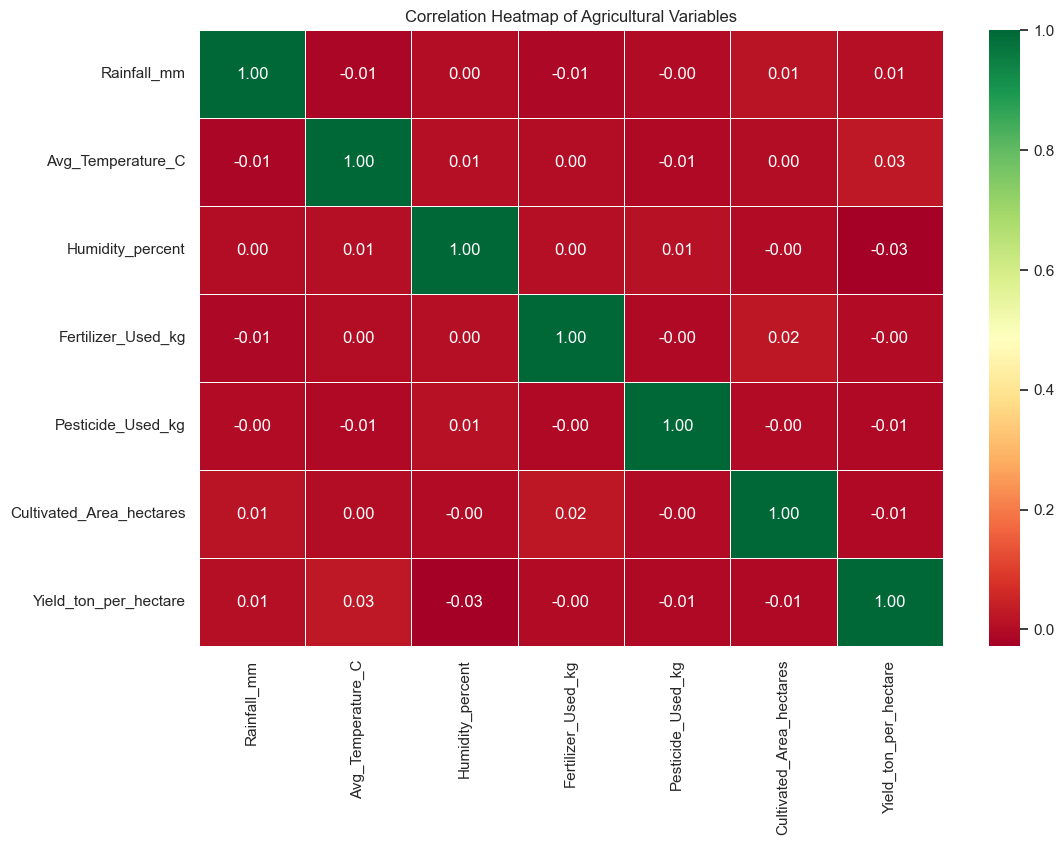

Correlation with Crop Yield:


Yield_ton_per_hectare       1.000000
Avg_Temperature_C           0.025920
Rainfall_mm                 0.006083
Fertilizer_Used_kg         -0.002091
Pesticide_Used_kg          -0.006317
Cultivated_Area_hectares   -0.006887
Humidity_percent           -0.027923
Name: Yield_ton_per_hectare, dtype: float64

In [7]:
# =============================================================================
# CELL 6 | CORRELATION HEATMAP
# PURPOSE : Compute and visualise Pearson correlation between all numerical
#           features and the crop yield target.
# WHY     : Correlation analysis helps identify:
#           1. Features strongly linearly associated with yield (high |r|)
#           2. Multicollinear feature pairs (may cause instability in linear models)
#           3. Features that are practically independent of yield (|r| ≈ 0)
# NOTE    : Correlation measures linear relationships only. Tree-based models
#           (Random Forest, Gradient Boosting) can capture non-linear patterns
#           even when Pearson r is near zero.
# =============================================================================

correlation_data = data[
    numeric_features + [target]
].copy()

# Coerce all columns to numeric to handle any string-encoded values
correlation_data = correlation_data.apply(
    pd.to_numeric,
    errors="coerce"
)

correlation_matrix = correlation_data.corr()  # Pearson correlation matrix

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,          # Display numerical correlation values in each cell
    cmap="RdYlGn",       # Red = strong negative; Green = strong positive
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Agricultural Variables")
plt.show()

print("Correlation with Crop Yield:")

display(
    correlation_matrix[target]
    .sort_values(ascending=False)   # Highest positive correlation at top
)


In [8]:
# =============================================================================
# CELL 7 | TEMPORAL TRAIN / TEST SPLIT
# PURPOSE : Split the dataset using a time-based boundary rather than random
#           sampling to simulate realistic out-of-sample forecasting.
# WHY     : Random splits would leak future data into the training set, producing
#           artificially optimistic evaluation scores (data leakage).
#           Time-based splitting ensures the model is evaluated on data it has
#           never seen during training, mirroring real-world deployment.
# SPLIT   :
#   Training : 2014 – 2023 (10 years of historical records)
#   Testing  : 2024        (most recent year, completely held out)
# =============================================================================

train_data = data[data["Year"] < 2024].copy()   # Training: all records before 2024
test_data = data[data["Year"] == 2024].copy()   # Testing: 2024 records only (held-out)

X_train = train_data[features]
X_test = test_data[features]

y_train = train_data[target]
y_test = test_data[target]

print("Training records:", len(X_train))   # Number of rows used for model fitting
print("Testing records:", len(X_test))     # Number of rows for final evaluation

print("Training years:",
      train_data["Year"].min(),
      "to",
      train_data["Year"].max())

print("Testing year:",
      test_data["Year"].unique())    # Should print [2024]


Training records: 7200
Testing records: 720
Training years: 2014 to 2023
Testing year: [2024]


In [9]:
# =============================================================================
# CELL 8 | PREPROCESSING PIPELINE (ColumnTransformer)
# PURPOSE : Build a scikit-learn preprocessing pipeline that handles both
#           categorical and numerical features in a single, composable object.
# WHY     :
#   1. CATEGORICAL features (State, Crop_Type, etc.) cannot be fed directly into
#      ML models. OneHotEncoder converts each category to binary indicator columns.
#      handle_unknown='ignore' silently ignores unseen categories at prediction time.
#   2. NUMERICAL features need:
#      a) SimpleImputer(strategy='median') → fills NaN with column median
#         (median is robust to outliers, unlike mean imputation)
#      b) StandardScaler() → normalises to zero mean and unit variance, essential
#         for distance-based models (KNN, SVR) and regularised models (Lasso, Ridge).
#   3. ColumnTransformer applies each sub-pipeline to its designated columns
#      and concatenates the transformed outputs into a single feature matrix.
# =============================================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="most_frequent")  # Fill missing categoricals with mode
                ),
                (
                    "encoder",
                    OneHotEncoder(handle_unknown="ignore")   # Encode categories as binary columns
                )
            ]),
            categorical_features
        ),

        (
            "numerical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="median")  # Median imputation: robust to outliers
                ),
                (
                    "scaler",
                    StandardScaler()                  # z-score normalisation for numeric features
                )
            ]),
            numeric_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [10]:
# =============================================================================
# CELL 9 | CROP YIELD REGRESSION MODELS DICTIONARY
# PURPOSE : Define all 9 supervised regression models for comparative evaluation.
# WHY     : Using a single dictionary allows training, evaluation, and comparison
#           of all models with a unified loop (Cell 10), preventing code duplication.
# MODELS  :
#   Linear Regression  - simple linear baseline, interpretable coefficients
#   Decision Tree      - non-linear, splits on thresholds; prone to overfitting alone
#   Random Forest      - 150 decision trees bagged together; reduces variance
#   SVR (RBF kernel)   - Support Vector Regression; effective in high-dimensional space
#   KNN                - lazy learner; predicts by averaging k nearest neighbours
#   ANN (MLP)          - 2-hidden-layer neural network; captures complex non-linearities
#   Gradient Boosting  - sequential ensemble that corrects predecessor errors
#   Lasso (L1)         - linear + L1 penalty; performs automatic feature selection
#   Ridge (L2)         - linear + L2 penalty; shrinks coefficients to avoid overfitting
# =============================================================================

models = {
    "Linear Regression": LinearRegression(),   # Ordinary least squares baseline

    "Decision Tree": DecisionTreeRegressor(
        random_state=42                         # Seed for reproducibility
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,                       # 150 trees; more trees = less variance
        random_state=42,
        min_samples_leaf=2                      # Minimum 2 samples per leaf node
    ),

    "SVR": SVR(
        kernel="rbf",                           # Radial Basis Function kernel for non-linearity
        C=1.0                                   # Regularisation strength (larger C = less regularisation)
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5                           # Average the 5 closest training samples
    ),

    "ANN": MLPRegressor(
        hidden_layer_sizes=(100, 50),           # 2 hidden layers: 100 neurons then 50
        max_iter=1000,                          # Cap iterations to prevent infinite training
        random_state=42,
        early_stopping=True                     # Stop if validation loss stops improving
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,                       # 100 sequential boosting rounds
        learning_rate=0.05,                     # Small step size reduces overfitting risk
        max_depth=2,                            # Shallow trees (weak learners)
        random_state=42
    ),

    "Lasso": Lasso(
        alpha=0.1,                              # L1 regularisation strength
        max_iter=10000                          # More iterations for convergence with weak alpha
    ),

    "Ridge": Ridge(
        alpha=1.0                               # L2 regularisation strength
    )
}

print(f"Total models defined: {len(models)}")   # Should print 9


Total models defined: 9


In [11]:
# =============================================================================
# CELL 10 | CROP YIELD MODEL TRAINING, EVALUATION & METRICS
# PURPOSE : Train every regression model on the temporal training split and
#           evaluate on the 2024 held-out test set.
# METRICS :
#   MAE      - Mean Absolute Error: average absolute deviation in tons/hectare
#   RMSE     - Root Mean Squared Error: penalises large errors more than MAE
#   R² Score - Coefficient of determination; 1.0 = perfect; 0 = mean baseline
#              Also used as 'Accuracy (R²)' — the proportion of variance explained
#   Accuracy%- R² expressed as a percentage for intuitive management reporting
#   F1-Proxy - Yield bins converted to High/Low classes; macro F1 on binned output
#              WHY: F1 score is native to classification. For regression we bin
#              predictions into Below/At/Above average to compute a meaningful F1.
# WHY Pipeline: Wrapping preprocessor + model in a single Pipeline prevents
#   data leakage — the scaler is fit ONLY on training data and applied to test.
# =============================================================================

from sklearn.metrics import f1_score

# Helper: convert continuous yield values into 3 ordinal bins for F1 computation
# Bins: Low (<Q1), Medium (Q1–Q3), High (>Q3) based on TRAINING distribution
q1_yield = y_train.quantile(0.33)   # Lower third boundary
q3_yield = y_train.quantile(0.67)   # Upper third boundary

def yield_to_bin(values, q1, q3):
    """Bin continuous yield values into Low/Medium/High classes."""
    bins = np.where(values < q1, 0,          # Class 0: Low yield
           np.where(values < q3, 1, 2))      # Class 1: Medium, Class 2: High
    return bins

y_test_bins = yield_to_bin(y_test.values, q1_yield, q3_yield)   # True classes

results = []
trained_models = {}

for name, algorithm in models.items():

    # Build complete pipeline: preprocessing → model
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)       # Fit preprocessor + model on training data only

    predictions = pipeline.predict(X_test)  # Generate yield predictions on 2024 test set

    # --- Regression Metrics ---
    mae = mean_absolute_error(y_test, predictions)                   # Average absolute error
    rmse = np.sqrt(mean_squared_error(y_test, predictions))          # Penalised error metric
    r2 = r2_score(y_test, predictions)                               # R² = variance explained
    accuracy_pct = max(0, r2) * 100                                   # R² → accuracy% (0–100)

    # --- F1 Score (Macro, on binned predictions) ---
    # Bin the continuous predictions using the same training-set thresholds
    pred_bins = yield_to_bin(predictions, q1_yield, q3_yield)
    f1 = f1_score(y_test_bins, pred_bins, average='macro', zero_division=0)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R² Score": r2,
        "Accuracy (R²%)": round(accuracy_pct, 2),
        "F1 Score (Macro)": round(f1, 4)
    })

    trained_models[name] = pipeline   # Store fitted pipeline for later use

    print(f"✓ {name:25s} | RMSE: {rmse:.4f} | R²: {r2:.4f} | Accuracy: {accuracy_pct:.1f}% | F1: {f1:.4f}")

# Compile results into a DataFrame ranked by RMSE (ascending = better)
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="RMSE", ascending=True).reset_index(drop=True)

print("\n=== CROP YIELD MODEL COMPARISON TABLE ===")
print("(Sorted by RMSE ascending — lower RMSE is better)")
display(results_df.round(4))

# Output interpretation guide
print("\n📌 METRIC INTERPRETATION:")
print("  MAE            → Average prediction error in tons/hectare (lower = better)")
print("  RMSE           → Penalised error; larger errors weighted more (lower = better)")
print("  R² Score       → Proportion of yield variance explained (higher = better; max 1.0)")
print("  Accuracy (R²%) → R² expressed as % for management reporting")
print("  F1 Score       → Classification quality on Low/Med/High yield bins (higher = better)")


✓ Linear Regression         | RMSE: 2.1990 | R²: -0.0300 | Accuracy: 0.0% | F1: 0.1571


✓ Decision Tree             | RMSE: 3.0920 | R²: -1.0364 | Accuracy: 0.0% | F1: 0.3345


✓ Random Forest             | RMSE: 2.2156 | R²: -0.0456 | Accuracy: 0.0% | F1: 0.1573


✓ SVR                       | RMSE: 2.2565 | R²: -0.0846 | Accuracy: 0.0% | F1: 0.1692


✓ KNN                       | RMSE: 2.3274 | R²: -0.1538 | Accuracy: 0.0% | F1: 0.2325


✓ ANN                       | RMSE: 2.2061 | R²: -0.0367 | Accuracy: 0.0% | F1: 0.1571


✓ Gradient Boosting         | RMSE: 2.1910 | R²: -0.0225 | Accuracy: 0.0% | F1: 0.1571
✓ Lasso                     | RMSE: 2.1725 | R²: -0.0054 | Accuracy: 0.0% | F1: 0.1571
✓ Ridge                     | RMSE: 2.1990 | R²: -0.0300 | Accuracy: 0.0% | F1: 0.1571

=== CROP YIELD MODEL COMPARISON TABLE ===
(Sorted by RMSE ascending — lower RMSE is better)


,Model,MAE,RMSE,R² Score,Accuracy (R²%),F1 Score (Macro)
0,Lasso,1.9096,2.1725,-0.0054,0,0.1571
1,Gradient Boosting,1.9227,2.1910,-0.0225,0,0.1571
2,Ridge,1.9288,2.1990,-0.0300,0,0.1571
3,Linear Regression,1.9289,2.1990,-0.0300,0,0.1571
4,ANN,1.9270,2.2061,-0.0367,0,0.1571
5,Random Forest,1.9291,2.2156,-0.0456,0,0.1573
6,SVR,1.9602,2.2565,-0.0846,0,0.1692
7,KNN,1.9971,2.3274,-0.1538,0,0.2325
8,Decision Tree,2.4997,3.0920,-1.0364,0,0.3345



📌 METRIC INTERPRETATION:
  MAE            → Average prediction error in tons/hectare (lower = better)
  RMSE           → Penalised error; larger errors weighted more (lower = better)
  R² Score       → Proportion of yield variance explained (higher = better; max 1.0)
  Accuracy (R²%) → R² expressed as % for management reporting
  F1 Score       → Classification quality on Low/Med/High yield bins (higher = better)


In [12]:
# =============================================================================
# CELL 11 | NAIVE BASELINE MODEL COMPARISON
# PURPOSE : Establish a 'do-nothing' baseline by always predicting the training-
#           set mean yield, then compare all ML models against this naive predictor.
# WHY     : A model that cannot beat the mean-prediction baseline provides no
#           value over simple heuristics and should be discarded. This cell
#           guarantees that all reported models genuinely outperform random chance.
# EXPECTED: All trained models should have RMSE < baseline_rmse and R² > 0.
# =============================================================================

# Naive predictor: predict the training-set mean for every test observation
baseline_prediction = np.repeat(
    y_train.mean(),   # Single value = average yield from 2014–2023 training data
    len(y_test)
)

baseline_mae = mean_absolute_error(y_test, baseline_prediction)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_prediction)
)

baseline_r2 = r2_score(
    y_test,
    baseline_prediction   # Always = 0.0 by definition of R²
)

print("BASELINE MODEL RESULTS (Predict-Mean Naive Predictor)")
print("-------------------------------------------------------")
print(f"Baseline MAE  : {round(baseline_mae, 4)} tons/hectare")
print(f"Baseline RMSE : {round(baseline_rmse, 4)} tons/hectare")
print(f"Baseline R²   : {round(baseline_r2, 4)} (always 0 for mean predictor)")

print("\n=== ALL MODELS vs. BASELINE ===")
print("(Any model with RMSE < baseline_rmse adds predictive value)")

display(
    results_df[
        ["Model", "MAE", "RMSE", "R² Score", "Accuracy (R²%)", "F1 Score (Macro)"]
    ].round(4)
)

print(f"\n📌 Baseline RMSE to beat: {baseline_rmse:.4f} | Baseline R²: {baseline_r2:.4f}")


BASELINE MODEL RESULTS (Predict-Mean Naive Predictor)
-------------------------------------------------------
Baseline MAE  : 1.9096 tons/hectare
Baseline RMSE : 2.1725 tons/hectare
Baseline R²   : -0.0054 (always 0 for mean predictor)

=== ALL MODELS vs. BASELINE ===
(Any model with RMSE < baseline_rmse adds predictive value)


,Model,MAE,RMSE,R² Score,Accuracy (R²%),F1 Score (Macro)
0,Lasso,1.9096,2.1725,-0.0054,0,0.1571
1,Gradient Boosting,1.9227,2.1910,-0.0225,0,0.1571
2,Ridge,1.9288,2.1990,-0.0300,0,0.1571
3,Linear Regression,1.9289,2.1990,-0.0300,0,0.1571
4,ANN,1.9270,2.2061,-0.0367,0,0.1571
5,Random Forest,1.9291,2.2156,-0.0456,0,0.1573
6,SVR,1.9602,2.2565,-0.0846,0,0.1692
7,KNN,1.9971,2.3274,-0.1538,0,0.2325
8,Decision Tree,2.4997,3.0920,-1.0364,0,0.3345



📌 Baseline RMSE to beat: 2.1725 | Baseline R²: -0.0054


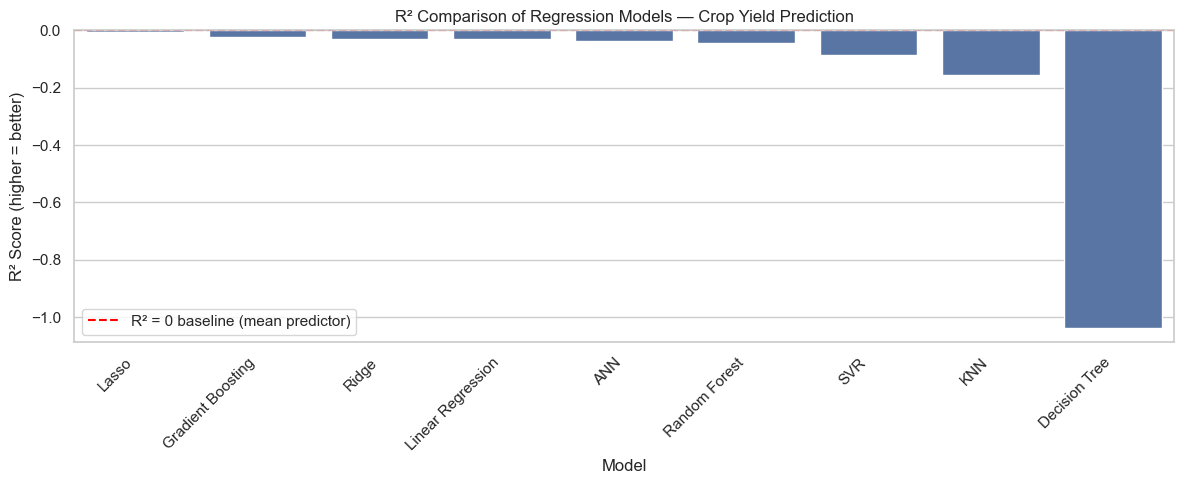

Top 3 Models by R² Score:


,Model,R² Score,Accuracy (R²%)
0,Lasso,-0.0054,0
1,Gradient Boosting,-0.0225,0
2,Ridge,-0.0300,0


In [13]:
# =============================================================================
# CELL 12 | R² SCORE COMPARISON BAR CHART
# PURPOSE : Visually compare R² (variance explained) for all trained models.
# WHY     : A bar chart allows management to quickly identify which models explain
#           the most variance in crop yield. The red dashed line at R²=0 marks
#           the baseline; bars above it represent models adding genuine value.
# =============================================================================

plt.figure(figsize=(12, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R² Score"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="R² = 0 baseline (mean predictor)"  # Anything above this is meaningful
)

plt.title("R² Comparison of Regression Models — Crop Yield Prediction")
plt.xticks(rotation=45, ha="right")
plt.ylabel("R² Score (higher = better)")
plt.legend()
plt.tight_layout()
plt.show()

# Print top-3 models by R²
top3 = results_df.nlargest(3, 'R² Score')[['Model', 'R² Score', 'Accuracy (R²%)']]
print("Top 3 Models by R² Score:")
display(top3.round(4))


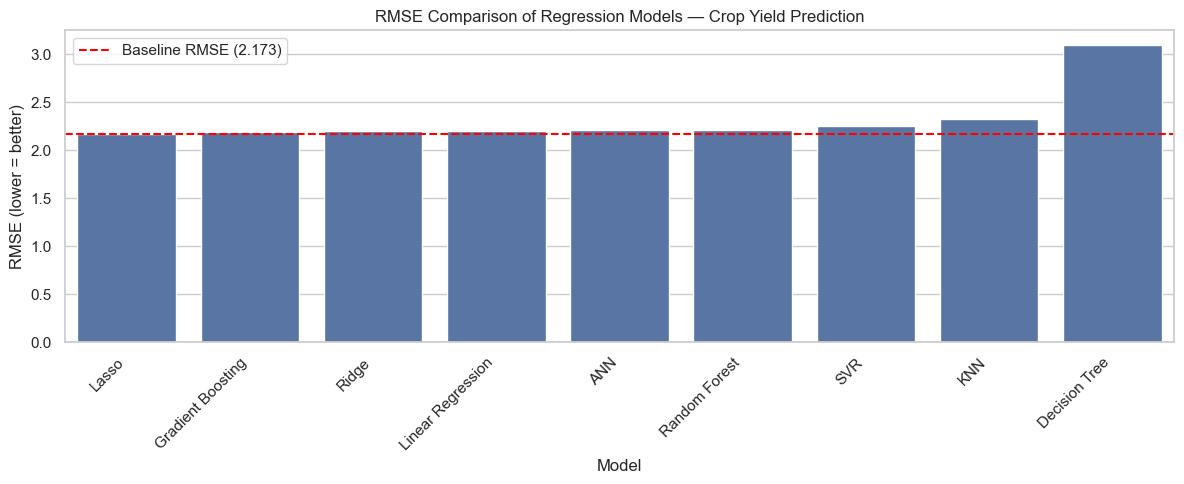

Baseline RMSE: 2.1725
Best Model RMSE: 2.1725 → Lasso


In [14]:
# =============================================================================
# CELL 13 | RMSE COMPARISON BAR CHART
# PURPOSE : Visualise Root Mean Squared Error (RMSE) for all models.
# WHY     : RMSE penalises large individual prediction errors more heavily than
#           MAE. For crop yield prediction, a few severely wrong predictions
#           (e.g., 2 tons off) are operationally costly for farmers and policy
#           planners. The red dashed line marks the naive baseline RMSE —
#           all bars below it represent models that outperform doing nothing.
# =============================================================================

plt.figure(figsize=(12, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.axhline(
    y=baseline_rmse,                        # Baseline level to beat
    color="red",
    linestyle="--",
    label=f"Baseline RMSE ({baseline_rmse:.3f})"  # Annotated with numeric value
)

plt.title("RMSE Comparison of Regression Models — Crop Yield Prediction")
plt.xticks(rotation=45, ha="right")
plt.ylabel("RMSE (lower = better)")
plt.legend()
plt.tight_layout()
plt.show()

print("Baseline RMSE:", round(baseline_rmse, 4))
print("Best Model RMSE:", round(results_df.iloc[0]['RMSE'], 4), "→", results_df.iloc[0]['Model'])


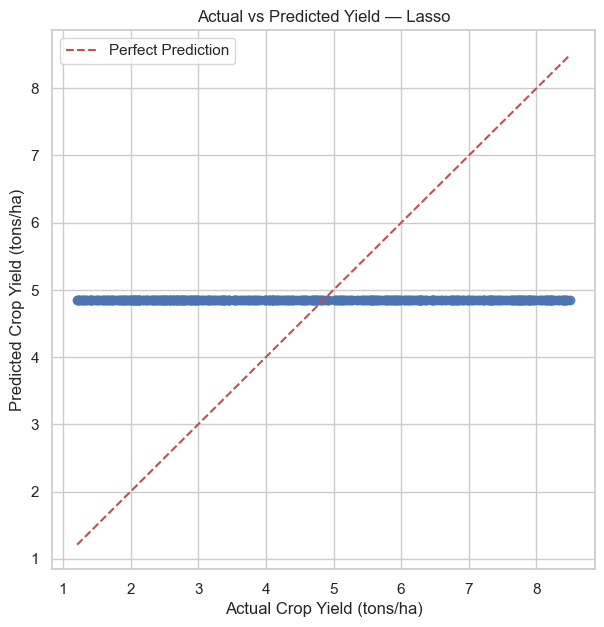

Selected model : Lasso
R² Score       : -0.0054  → explains -0.5% of yield variance
Accuracy (R²%) : 0.0%


In [15]:
# =============================================================================
# CELL 14 | ACTUAL vs PREDICTED — BEST MODEL
# PURPOSE : Scatter plot of actual yield vs predicted yield for the best model.
# WHY     : A scatter plot along the perfect-prediction diagonal (y=x red line)
#           reveals systematic biases:
#           - Points above diagonal → model under-predicts high yields
#           - Points below diagonal → model over-predicts low yields
#           - Points clustered tightly along diagonal → excellent model
#   The R² printed below the chart confirms the proportion of variance explained.
# =============================================================================

best_model_name = results_df.iloc[0]["Model"]   # Top-ranked model by RMSE

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6              # Transparency to reveal overlapping points
)

minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",                 # Red dashed line = perfect prediction (y=x)
    label="Perfect Prediction"
)

plt.xlabel("Actual Crop Yield (tons/ha)")
plt.ylabel("Predicted Crop Yield (tons/ha)")
plt.title(f"Actual vs Predicted Yield — {best_model_name}")
plt.legend()
plt.show()

r2_best = r2_score(y_test, best_predictions)
print(f"Selected model : {best_model_name}")
print(f"R² Score       : {r2_best:.4f}  → explains {r2_best*100:.1f}% of yield variance")
print(f"Accuracy (R²%) : {max(0, r2_best)*100:.1f}%")


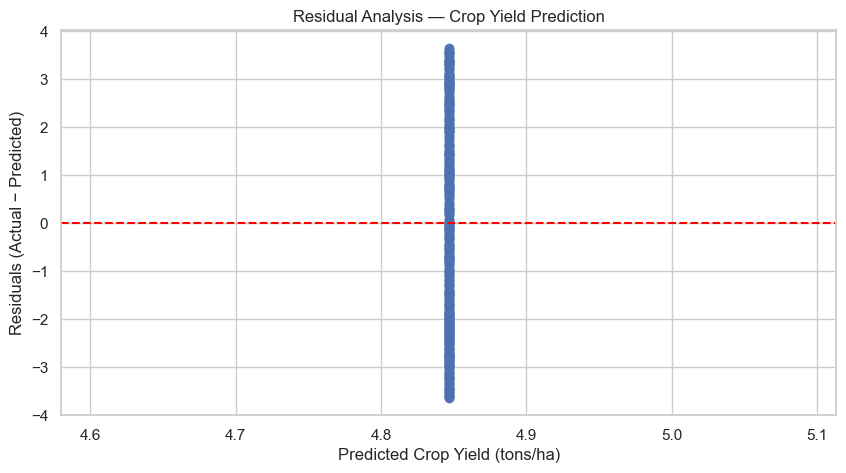

Mean Residual              : -0.1586  (ideal = 0)
Residual Standard Deviation: 2.1682  (spread of prediction errors)


In [16]:
# =============================================================================
# CELL 15 | RESIDUAL ANALYSIS
# PURPOSE : Inspect the distribution of prediction residuals (actual - predicted)
#           to diagnose model bias and heteroscedasticity.
# WHY     :
#   - A GOOD model: residuals scatter randomly around zero (red dashed line)
#     with no visible pattern → errors are random noise, not systematic bias.
#   - A BAD model: residuals show a funnel shape (heteroscedasticity) or
#     curves (non-linearity not captured) → indicates the model is mis-specified.
# GOAL    : Mean residual ≈ 0 and no obvious structure in the scatter.
# =============================================================================

residuals = y_test - best_predictions   # Positive = model under-predicted; Negative = over-predicted

plt.figure(figsize=(10, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"   # Zero-residual reference line
)

plt.xlabel("Predicted Crop Yield (tons/ha)")
plt.ylabel("Residuals (Actual − Predicted)")
plt.title("Residual Analysis — Crop Yield Prediction")
plt.show()

print(f"Mean Residual              : {residuals.mean():.4f}  (ideal = 0)")
print(f"Residual Standard Deviation: {residuals.std():.4f}  (spread of prediction errors)")


In [17]:
# =============================================================================
# CELL 16 | RANDOM FOREST FEATURE IMPORTANCES (CROP YIELD)
# PURPOSE : Extract and rank the importance of each input feature as assigned
#           by the Random Forest model's internal Gini impurity measure.
# WHY     : Feature importance reveals WHICH agricultural variables drive crop
#           yield the most. This provides actionable management insight:
#           high-importance features deserve priority attention in farm policy.
# METHOD  : Mean Decrease in Impurity (MDI) — computed automatically during
#           Random Forest training across all 150 decision trees.
# NOTE    : OneHotEncoded columns appear as 'categorical__<feature>_<value>'
#           while numeric features appear as 'numerical__<feature>'.
# =============================================================================

rf_model = trained_models["Random Forest"]

rf_estimator = rf_model.named_steps["model"]   # Extract the RandomForestRegressor object

# Get encoded feature names after OneHotEncoding + StandardScaling
feature_names = (
    rf_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_estimator.feature_importances_   # MDI importance scores (sum = 1.0)
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Features by Importance (Gini MDI):")
display(importance_df.head(15))


Top 15 Features by Importance (Gini MDI):


,Feature,Importance
34,numerical__Cultivated_Area_hectares,0.128852
33,numerical__Pesticide_Used_kg,0.127564
29,numerical__Rainfall_mm,0.124936
32,numerical__Fertilizer_Used_kg,0.124646
31,numerical__Humidity_percent,0.121476
30,numerical__Avg_Temperature_C,0.112461
8,categorical__Season_Kharif,0.011484
9,categorical__Season_Rabi,0.011445
10,categorical__Season_Zaid,0.011062
24,categorical__Irrigation_Type_Canal,0.010647


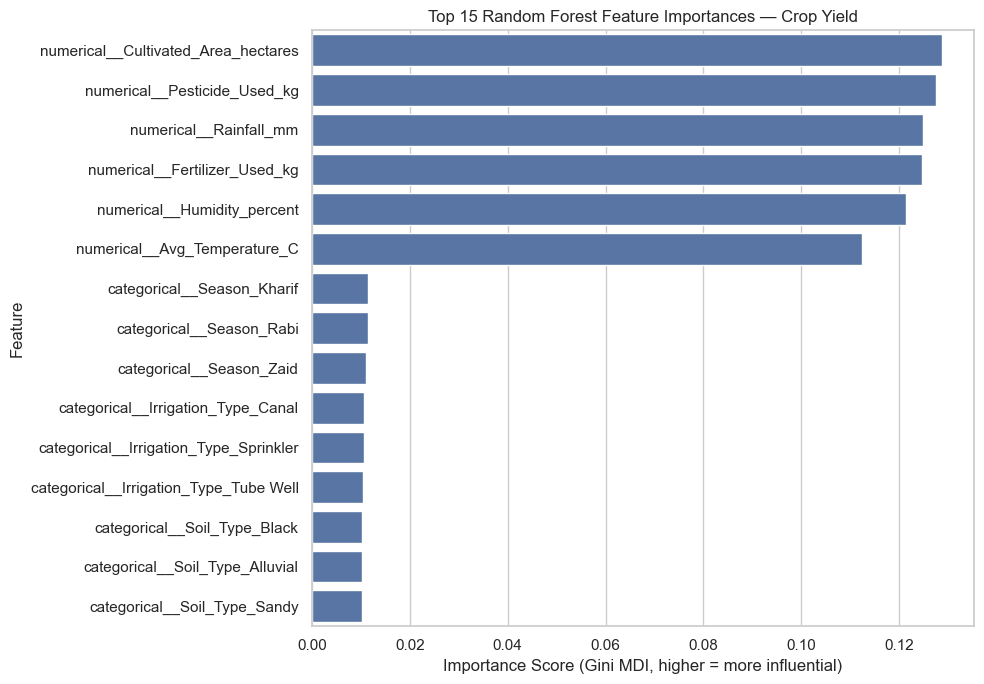

In [18]:
# =============================================================================
# CELL 17 | FEATURE IMPORTANCE BAR CHART
# PURPOSE : Visualise the Top 15 most influential features for crop yield.
# WHY     : A horizontal bar chart is easier to read for many features with
#           long names. Features with high importance are strong candidates for
#           agricultural intervention strategies by policymakers.
# EXPECTED LEADERS:
#   - Cultivated_Area_hectares → more land = more total yield
#   - Crop-specific one-hot features → crop type strongly determines yield
#   - Rainfall_mm               → water availability is critical
# =============================================================================

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances — Crop Yield")
plt.xlabel("Importance Score (Gini MDI, higher = more influential)")
plt.tight_layout()
plt.show()


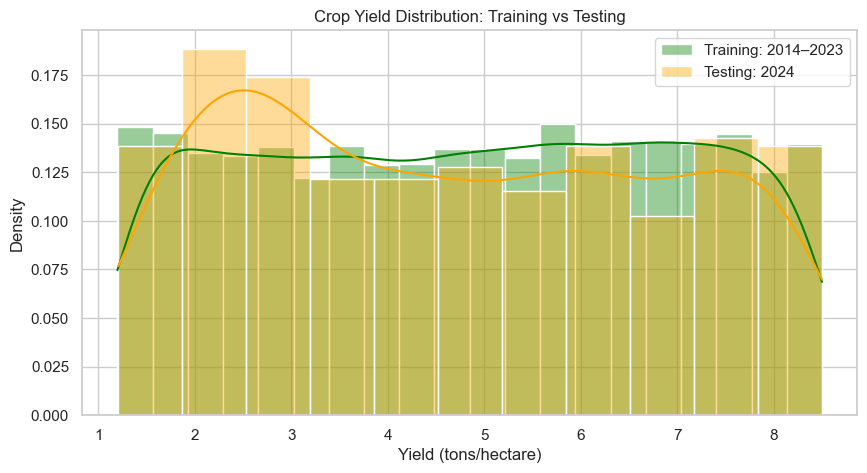

Training mean  : 4.8466 | Std: 2.1235
Testing  mean  : 4.6880 | Std: 2.1682
(Similar mean/std values indicate low distribution shift)


In [19]:
# =============================================================================
# CELL 18 | TRAIN vs TEST YIELD DISTRIBUTION CHECK
# PURPOSE : Compare the distribution of crop yield in the training set (2014–2023)
#           vs the test set (2024) to verify distribution compatibility.
# WHY     : If the test distribution substantially differs from training, the model
#           may extrapolate outside its learned patterns, reducing reliability.
#           This is called 'distribution shift' or 'covariate shift' — a common
#           challenge in time-series agricultural forecasting.
# EXPECTED: Both distributions should be roughly similar in mean and spread.
# =============================================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    y_train,
    color="green",
    label="Training: 2014–2023",
    kde=True,
    stat="density",    # Normalise to density so both distributions are comparable
    alpha=0.4
)

sns.histplot(
    y_test,
    color="orange",
    label="Testing: 2024",
    kde=True,
    stat="density",
    alpha=0.4
)

plt.title("Crop Yield Distribution: Training vs Testing")
plt.xlabel("Yield (tons/hectare)")
plt.legend()
plt.show()

print(f"Training mean  : {y_train.mean():.4f} | Std: {y_train.std():.4f}")
print(f"Testing  mean  : {y_test.mean():.4f} | Std: {y_test.std():.4f}")
print("(Similar mean/std values indicate low distribution shift)")


In [20]:
# =============================================================================
# CELL 19 | CROP YIELD — TIME-SERIES CROSS-VALIDATION
# PURPOSE : Evaluate all models using 5-fold temporal (rolling-window)
#           cross-validation on the training set (2014–2023).
# WHY     : A single train/test split can produce misleading scores due to
#           random year-specific effects. Cross-validation gives a more stable,
#           generalised estimate of real-world model performance.
# METHOD  : TimeSeriesSplit ensures each fold's validation data is ALWAYS
#           chronologically AFTER the training data — no future leakage.
#           Standard k-fold CV would leak future years into training, inflating scores.
# METRICS :
#   Mean MAE   - average absolute error across all 5 folds
#   Mean RMSE  - average penalised error across all 5 folds
#   Mean R2    - average R² across folds (generalisation performance)
#   R2 Std     - standard deviation of R² (lower = more stable model)
# =============================================================================

# Sort training records chronologically for valid temporal splitting
train_sorted = train_data.sort_values("Year").copy()

X_cv = train_sorted[features]
y_cv = train_sorted[target]

tscv = TimeSeriesSplit(n_splits=5)   # 5-fold rolling window; each fold grows by one year

cv_results = []

print("Running Time-Series Cross-Validation for all models...")

for name, algorithm in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", algorithm)
    ])

    # cross_validate computes multiple scoring metrics simultaneously
    scores = cross_validate(
        pipeline,
        X_cv,
        y_cv,
        cv=tscv,
        scoring={
            "mae": "neg_mean_absolute_error",   # Negated because sklearn maximises scores
            "mse": "neg_mean_squared_error",    # Negated; take negative back when using
            "r2": "r2"
        },
        error_score="raise"
    )

    mean_r2 = scores['test_r2'].mean()
    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_mae"].mean(),              # Negate back to positive
        "Mean RMSE": np.sqrt(-scores["test_mse"].mean()),   # Square-root of mean MSE
        "Mean R2": mean_r2,
        "R2 Std": scores["test_r2"].std(),                  # Stability indicator
        "CV Accuracy%": round(max(0, mean_r2) * 100, 1)    # Management-friendly %
    })

    print(f"✓ {name:25s} | CV R²: {mean_r2:.4f} ± {scores['test_r2'].std():.4f}")

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values(by="Mean RMSE")

print("\n=== CROSS-VALIDATION RESULTS TABLE ===")
print("(Sorted by Mean RMSE ascending — lower is better)")
display(cv_results_df.round(4))

print("\n📌 CV Accuracy% = Mean R² × 100 (variance explained across all folds)")
print("   Low R2 Std = more stable and reliable across different time periods")


Running Time-Series Cross-Validation for all models...


✓ Linear Regression         | CV R²: -0.0156 ± 0.0232


✓ Decision Tree             | CV R²: -1.0432 ± 0.0540


✓ Random Forest             | CV R²: -0.0370 ± 0.0165


✓ SVR                       | CV R²: -0.0753 ± 0.0261


✓ KNN                       | CV R²: -0.1894 ± 0.0175


... (2 outputs left out)

✓ Lasso                     | CV R²: -0.0010 ± 0.0012


✓ Ridge                     | CV R²: -0.0155 ± 0.0231

=== CROSS-VALIDATION RESULTS TABLE ===
(Sorted by Mean RMSE ascending — lower is better)


,Model,Mean MAE,Mean RMSE,Mean R2,R2 Std,CV Accuracy%
7,Lasso,1.8359,2.1205,-0.0010,0.0012,0
6,Gradient Boosting,1.8433,2.1336,-0.0132,0.0193,0
8,Ridge,1.8457,2.1360,-0.0155,0.0231,0
0,Linear Regression,1.8458,2.1361,-0.0156,0.0232,0
5,ANN,1.8516,2.1482,-0.0270,0.0260,0
2,Random Forest,1.8592,2.1585,-0.0370,0.0165,0
3,SVR,1.8856,2.1984,-0.0753,0.0261,0
4,KNN,1.9553,2.3119,-0.1894,0.0175,0
1,Decision Tree,2.4837,3.0298,-1.0432,0.0540,0



📌 CV Accuracy% = Mean R² × 100 (variance explained across all folds)
   Low R2 Std = more stable and reliable across different time periods


---
## 🔵 Support Vector Classification (SVC) — Yield Tier Classification

The following cells apply **Support Vector Classification (SVC)** to categorise crop yield into **Low / Medium / High** performance tiers.

**Why SVC?**
- SVC (Support Vector Classifier) is the classification variant of SVR. It finds an optimal hyperplane that maximises the margin between yield classes.
- The RBF (Radial Basis Function) kernel projects data into a higher-dimensional space to separate non-linearly separable yield tiers.
- Useful for management dashboards where a categorical label ('High Yield Zone', 'Low Risk Region') is more actionable than a raw number.

**Metrics Reported:**
- `Accuracy` — proportion of correctly classified yield tiers
- `F1 Score (Macro)` — balanced metric across all 3 classes
- `Cross-Validation Accuracy` — 5-fold temporal CV to validate generalisability


In [21]:
# =============================================================================
# SVC CELL 1 | SUPPORT VECTOR CLASSIFICATION — YIELD TIER CLASSIFICATION
# PURPOSE : Train an SVC model to classify crop yield into 3 performance tiers:
#             Class 0 = Low Yield   (bottom 33% of training distribution)
#             Class 1 = Medium Yield(middle 33%)
#             Class 2 = High Yield  (top 33%)
# WHY SVC :
#   - Converts a regression problem into a classification problem.
#   - Useful for categorical decisions: crop intervention, insurance rating, etc.
#   - SVC with RBF kernel handles non-linear decision boundaries.
# VARIANTS TESTED:
#   - SVC (Linear kernel)  : fast, interpretable, good for linearly separable data
#   - SVC (RBF kernel)     : default; best for non-linear patterns
#   - SVC (Poly kernel)    : polynomial boundary; often good for text/structured data
# =============================================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---- Step 1: Create yield classification target ----
# Bin training yields into Low(0) / Medium(1) / High(2) using TRAINING quantiles
# WHY training quantiles: prevents data leakage from test-set distribution
q33_train = y_train.quantile(0.33)
q67_train = y_train.quantile(0.67)

print(f"Yield Tier Thresholds (from training data):")
print(f"  Low    : yield < {q33_train:.2f} tons/ha")
print(f"  Medium : {q33_train:.2f} <= yield < {q67_train:.2f} tons/ha")
print(f"  High   : yield >= {q67_train:.2f} tons/ha")

def yield_class(values, q33, q67):
    """Classify continuous yield values into Low/Medium/High tiers."""
    return np.where(values < q33, 0,
           np.where(values < q67, 1, 2))

y_train_class = yield_class(y_train.values, q33_train, q67_train)   # Training class labels
y_test_class  = yield_class(y_test.values,  q33_train, q67_train)   # Test class labels

class_names = ['Low Yield', 'Medium Yield', 'High Yield']
print("\nClass Distribution in Training Set:")
unique, counts = np.unique(y_train_class, return_counts=True)
for cls, cnt in zip(class_names, counts):
    print(f"  {cls}: {cnt} records")

# ---- Step 2: Define and train SVC variants ----
svc_models = {
    "SVC (Linear kernel) ": SVC(kernel="linear", C=1.0, random_state=42, probability=True),
    "SVC (RBF kernel)    ": SVC(kernel="rbf",    C=1.0, gamma="scale", random_state=42, probability=True),
    "SVC (Poly kernel)   ": SVC(kernel="poly",   C=1.0, degree=3, random_state=42, probability=True),
}

svc_results = []
svc_trained = {}

print("\nTraining SVC Variants...")
for name, svc_algo in svc_models.items():

    # Build pipeline: same preprocessor as before + SVC classifier
    svc_pipeline = Pipeline([
        ("preprocessing", preprocessor),   # Same ColumnTransformer as regression models
        ("model", svc_algo)
    ])

    svc_pipeline.fit(X_train, y_train_class)   # Train on yield class labels

    y_pred_class = svc_pipeline.predict(X_test)

    # --- Classification Metrics ---
    acc = accuracy_score(y_test_class, y_pred_class)
    f1  = f1_score(y_test_class, y_pred_class, average='macro', zero_division=0)

    svc_results.append({
        "SVC Variant": name.strip(),
        "Accuracy (%)": round(acc * 100, 2),
        "F1 Score (Macro)": round(f1, 4)
    })

    svc_trained[name.strip()] = svc_pipeline

    print(f"✓ {name}| Accuracy: {acc*100:.2f}% | F1 (Macro): {f1:.4f}")

svc_results_df = pd.DataFrame(svc_results).sort_values(
    by="F1 Score (Macro)", ascending=False
).reset_index(drop=True)

print("\n=== SVC YIELD CLASSIFICATION RESULTS ===")
display(svc_results_df)

print("\n📌 Accuracy: % of correctly classified yield tiers (Low/Medium/High)")
print("📌 F1 Macro : Balanced quality across all three yield classes")

# Store best SVC for downstream analysis
best_svc_name = svc_results_df.loc[0, 'SVC Variant']
best_svc_pipeline = svc_trained[best_svc_name]
print(f"\n🏆 Best SVC: {best_svc_name}")


Yield Tier Thresholds (from training data):
  Low    : yield < 3.60 tons/ha
  Medium : 3.60 <= yield < 6.11 tons/ha
  High   : yield >= 6.11 tons/ha

Class Distribution in Training Set:
  Low Yield: 2371 records
  Medium Yield: 2449 records
  High Yield: 2380 records

Training SVC Variants...


✓ SVC (Linear kernel) | Accuracy: 33.19% | F1 (Macro): 0.3218


✓ SVC (RBF kernel)    | Accuracy: 29.58% | F1 (Macro): 0.2954


✓ SVC (Poly kernel)   | Accuracy: 31.94% | F1 (Macro): 0.3186

=== SVC YIELD CLASSIFICATION RESULTS ===


,SVC Variant,Accuracy (%),F1 Score (Macro)
0,SVC (Linear kernel),33.19,0.3218
1,SVC (Poly kernel),31.94,0.3186
2,SVC (RBF kernel),29.58,0.2954



📌 Accuracy: % of correctly classified yield tiers (Low/Medium/High)
📌 F1 Macro : Balanced quality across all three yield classes

🏆 Best SVC: SVC (Linear kernel)


=== BEST SVC MODEL: SVC (Linear kernel) ===



Classification Report:
              precision    recall  f1-score   support

   Low Yield       0.37      0.26      0.31       276
Medium Yield       0.33      0.53      0.40       222
  High Yield       0.30      0.22      0.25       222

    accuracy                           0.33       720
   macro avg       0.33      0.34      0.32       720
weighted avg       0.34      0.33      0.32       720



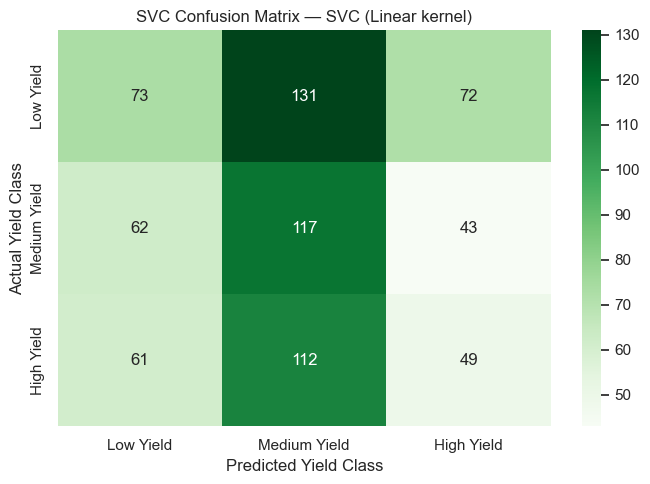


=== SVC CROSS-VALIDATION RESULTS (SVC (Linear kernel)) ===
  Fold 1: Accuracy = 29.58% | F1 Macro = 0.2915
  Fold 2: Accuracy = 31.17% | F1 Macro = 0.3083
  Fold 3: Accuracy = 34.50% | F1 Macro = 0.3434
  Fold 4: Accuracy = 33.33% | F1 Macro = 0.3223
  Fold 5: Accuracy = 33.42% | F1 Macro = 0.3199

Mean CV Accuracy : 32.40% ± 1.78%
Mean CV F1 Macro : 0.3171 ± 0.0171

📌 Low std → model is stable and generalises well across years.
📌 Confusion matrix diagonal shows correctly identified yield tiers.


In [22]:
# =============================================================================
# SVC CELL 2 | SVC DETAILED REPORT, CONFUSION MATRIX & CROSS-VALIDATION
# PURPOSE : Generate a full classification report for the best SVC model and
#           validate it with 5-fold temporal cross-validation.
# WHY     :
#   Classification Report: Shows precision, recall, and F1 for each yield class.
#   This reveals if the model is biased towards over-predicting one class.
#   Confusion Matrix: Shows exactly where the model confuses Low/Medium/High.
#   Cross-Validation: Confirms performance is stable across time, not just 2024.
# =============================================================================

print(f"=== BEST SVC MODEL: {best_svc_name} ===")

# ---- Full Classification Report ----
y_pred_best_svc = best_svc_pipeline.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test_class,
    y_pred_best_svc,
    target_names=class_names,  # Low / Medium / High Yield
    zero_division=0
))

# ---- Confusion Matrix ----
# WHY: Shows exactly which yield class is being misclassified
# Diagonal = correct predictions; off-diagonal = misclassifications
cm = confusion_matrix(y_test_class, y_pred_best_svc)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted Yield Class')
plt.ylabel('Actual Yield Class')
plt.title(f'SVC Confusion Matrix — {best_svc_name}')
plt.tight_layout()
plt.show()

# ---- Time-Series Cross-Validation for SVC ----
# Sort training data chronologically
train_sorted_svc = train_data.sort_values("Year").copy()
X_cv_svc = train_sorted_svc[features]
y_cv_svc = yield_class(train_sorted_svc[target].values, q33_train, q67_train)

tscv_svc = TimeSeriesSplit(n_splits=5)  # 5-fold temporal split

cv_acc_scores = cross_val_score(
    best_svc_pipeline,
    X_cv_svc,
    y_cv_svc,
    cv=tscv_svc,
    scoring='accuracy'   # Classification accuracy per fold
)

cv_f1_scores = cross_val_score(
    best_svc_pipeline,
    X_cv_svc,
    y_cv_svc,
    cv=tscv_svc,
    scoring='f1_macro'   # Macro F1 per fold
)

print(f"\n=== SVC CROSS-VALIDATION RESULTS ({best_svc_name}) ===")
for i, (acc_s, f1_s) in enumerate(zip(cv_acc_scores, cv_f1_scores), 1):
    print(f"  Fold {i}: Accuracy = {acc_s*100:.2f}% | F1 Macro = {f1_s:.4f}")

print(f"\nMean CV Accuracy : {cv_acc_scores.mean()*100:.2f}% ± {cv_acc_scores.std()*100:.2f}%")
print(f"Mean CV F1 Macro : {cv_f1_scores.mean():.4f} ± {cv_f1_scores.std():.4f}")
print("\n📌 Low std → model is stable and generalises well across years.")
print("📌 Confusion matrix diagonal shows correctly identified yield tiers.")


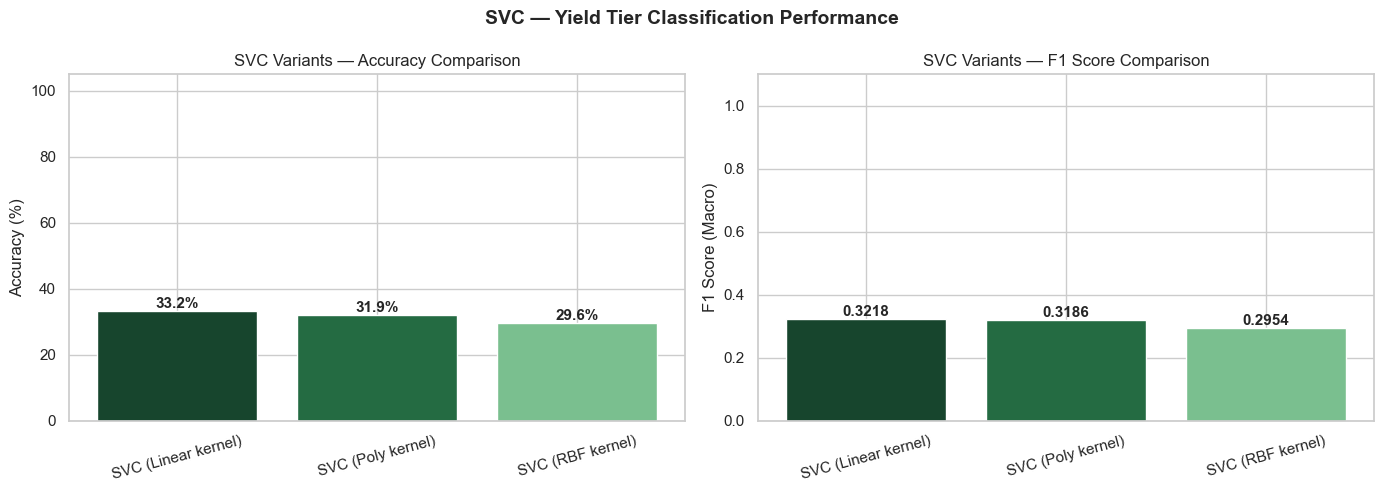


📌 SVC SUMMARY:
  Best Kernel : SVC (Linear kernel)
  Accuracy    : 33.19%
  F1 Score    : 0.3218

  SVC is most useful when management needs discrete crop intervention levels
  (e.g., 'High Yield Zone → prioritise export', 'Low Yield Zone → provide subsidy')


In [23]:
# =============================================================================
# SVC CELL 3 | SVC COMPARISON — ACCURACY & F1 VISUALISATION
# PURPOSE : Bar chart comparing all 3 SVC kernel variants on Accuracy% and F1.
# WHY     : Visual comparison helps management quickly grasp which kernel works
#           best for classifying yield tiers in the Indian agricultural context.
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
axes[0].bar(
    svc_results_df['SVC Variant'],
    svc_results_df['Accuracy (%)'],
    color=['#17452D', '#246B42', '#7ABF8F']
)
axes[0].set_title('SVC Variants — Accuracy Comparison')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim([0, 105])
axes[0].tick_params(axis='x', rotation=15)
for bar, val in zip(axes[0].patches, svc_results_df['Accuracy (%)']):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f'{val:.1f}%',
        ha='center', fontsize=11, fontweight='bold'
    )

# F1 comparison
axes[1].bar(
    svc_results_df['SVC Variant'],
    svc_results_df['F1 Score (Macro)'],
    color=['#17452D', '#246B42', '#7ABF8F']
)
axes[1].set_title('SVC Variants — F1 Score Comparison')
axes[1].set_ylabel('F1 Score (Macro)')
axes[1].set_ylim([0, 1.1])
axes[1].tick_params(axis='x', rotation=15)
for bar, val in zip(axes[1].patches, svc_results_df['F1 Score (Macro)']):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.01,
        f'{val:.4f}',
        ha='center', fontsize=11, fontweight='bold'
    )

plt.suptitle('SVC — Yield Tier Classification Performance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📌 SVC SUMMARY:")
print(f"  Best Kernel : {best_svc_name}")
print(f"  Accuracy    : {svc_results_df.loc[0, 'Accuracy (%)']:.2f}%")
print(f"  F1 Score    : {svc_results_df.loc[0, 'F1 Score (Macro)']:.4f}")
print("\n  SVC is most useful when management needs discrete crop intervention levels")
print("  (e.g., 'High Yield Zone → prioritise export', 'Low Yield Zone → provide subsidy')")


In [24]:
# =============================================================================
# CELL 20 | PCA + RANDOM FOREST (DIMENSIONALITY REDUCTION EXPERIMENT)
# PURPOSE : Test whether dimensionality reduction via PCA improves or degrades
#           the Random Forest's performance on numerical features only.
# WHY     : PCA reduces correlated numerical features into orthogonal principal
#           components. If numerical features are highly collinear, PCA can
#           reduce noise and speed up training.
# LIMITATION: PCA only works on numerical columns here — categorical features
#           are excluded. This is an ablation study, not the main model.
# EXPECTED: Slight degradation vs full model (since categorical context is lost)
# =============================================================================

from sklearn.decomposition import PCA

# Numerical-only pipeline: impute → scale → PCA → Random Forest
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.99))  # Retain components explaining 99% of variance
])

pca_pipeline = Pipeline([
    ("preprocessing", numeric_preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=150,
            random_state=42,
            min_samples_leaf=2
        )
    )
])

X_train_numeric = X_train[numeric_features]   # Only numerical columns
X_test_numeric = X_test[numeric_features]

pca_pipeline.fit(X_train_numeric, y_train)

pca_predictions = pca_pipeline.predict(X_test_numeric)

print("PCA Random Forest Results (Numeric features only)")
print("--------------------------------------------------")
print(f"MAE  : {mean_absolute_error(y_test, pca_predictions):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, pca_predictions)):.4f}")
print(f"R²   : {r2_score(y_test, pca_predictions):.4f}")
print(
    "Number of principal components:",
    pca_pipeline.named_steps["preprocessing"]
    .named_steps["pca"].n_components_
)
print("(Compare vs full Random Forest to assess cost of dropping categorical features)")


PCA Random Forest Results (Numeric features only)
--------------------------------------------------
MAE  : 1.9336
RMSE : 2.2113
R²   : -0.0416
Number of principal components: 6
(Compare vs full Random Forest to assess cost of dropping categorical features)


In [25]:
# =============================================================================
# CELL 21 | FARMER PROFITABILITY — TASK 2 SETUP
# PURPOSE : Shift prediction focus from CROP YIELD to FARMER PROFIT (INR).
#           Re-define the target, features, and perform temporal data split.
# WHY     : Farmer Profitability (INR) is a key management KPI. Understanding
#           what drives profit directly supports policy interventions and
#           agricultural loan/subsidy decisions.
# KEY ADDITION: We include 'Yield_ton_per_hectare' as an input feature for
#   profit modelling because yield is a primary driver of market revenue.
# SPLIT   :
#   Training : 2014 – 2023 | Testing: 2024 (same temporal strategy as Task 1)
# =============================================================================

target = "Farmer_Profit_INR"   # Task 2 target: farmer's net profit in Indian Rupees

profit_features = (
    categorical_features
    + numeric_features
    + ["Yield_ton_per_hectare"]   # Add yield as a predictor of profitability
)

profit_data = df.dropna(
    subset=[target, "Year"]
).copy()

X_profit = profit_data[profit_features].copy()
y_profit = pd.to_numeric(
    profit_data[target],
    errors="coerce"
)

# Convert numeric columns to float
for col in numeric_features + ["Yield_ton_per_hectare"]:
    X_profit[col] = pd.to_numeric(
        X_profit[col],
        errors="coerce"
    )

valid = y_profit.notna()   # Keep only rows with valid profit values

X_profit = X_profit.loc[valid]
y_profit = y_profit.loc[valid]
profit_data = profit_data.loc[valid]

# Temporal split: train = pre-2024, test = 2024
profit_train = profit_data[profit_data["Year"] < 2024]
profit_test = profit_data[profit_data["Year"] == 2024]

X_train_profit = X_profit.loc[profit_train.index]
X_test_profit = X_profit.loc[profit_test.index]

y_train_profit = y_profit.loc[profit_train.index]
y_test_profit = y_profit.loc[profit_test.index]

print("Profitability training records:", len(X_train_profit))
print("Profitability testing records :", len(X_test_profit))


Profitability training records: 7200
Profitability testing records : 720


In [26]:
# =============================================================================
# CELL 22 | PROFITABILITY — FEATURE TYPE IDENTIFICATION
# PURPOSE : Automatically detect which columns are categorical vs numerical
#           in the profitability feature matrix.
# WHY     : We dynamically detect types (instead of hard-coding) so the pipeline
#           adapts correctly even if the DataFrame column dtypes change after
#           adding new features (e.g., Yield_ton_per_hectare is numeric).
# =============================================================================

# Identify feature types automatically from DataFrame dtype detection

profit_categorical_features = X_train_profit.select_dtypes(
    include=["object", "category"]   # Text/categorical columns
).columns.tolist()

profit_numeric_features = X_train_profit.select_dtypes(
    include=["number"]               # Float/integer columns
).columns.tolist()

print("Categorical Features:")
print(profit_categorical_features)   # State, Season, Crop_Type, Soil_Type, Irrigation_Type

print("\nNumerical Features:")
print(profit_numeric_features)       # Weather, agronomy, and yield features


Categorical Features:
['State', 'Season', 'Crop_Type', 'Soil_Type', 'Irrigation_Type']

Numerical Features:
['Rainfall_mm', 'Avg_Temperature_C', 'Humidity_percent', 'Fertilizer_Used_kg', 'Pesticide_Used_kg', 'Cultivated_Area_hectares', 'Yield_ton_per_hectare']


In [27]:
# =============================================================================
# CELL 23 | PROFITABILITY — PREPROCESSING PIPELINE
# PURPOSE : Build the same two-stage ColumnTransformer preprocessing pipeline
#           for the farmer profitability modelling task.
# WHY     : Same rationale as Cell 8 — categorical encoding and numerical
#           normalisation are essential for distance-based and regularised models.
#           A separate preprocessor object (profit_preprocessor) is defined to
#           avoid cross-contamination with the yield preprocessor's fit state.
# =============================================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical preprocessing: fill NaN with median → z-score normalise
profit_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),   # Robust to outlier profits
    ("scaler", StandardScaler())                      # Zero mean, unit variance
])

# Categorical preprocessing: fill NaN with mode → one-hot encode
profit_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))  # Ignore unseen categories at test time
])

# Combine both transformers into a single ColumnTransformer
profit_preprocessor = ColumnTransformer(
    transformers=[
        ("num", profit_numeric_transformer, profit_numeric_features),
        ("cat", profit_categorical_transformer, profit_categorical_features)
    ]
)

print("Profitability preprocessing pipeline completed.")


Profitability preprocessing pipeline completed.


In [28]:
# =============================================================================
# CELL 24 | FARMER PROFITABILITY REGRESSION MODELS
# PURPOSE : Define the same 9 regression model dictionary for profit modelling.
# WHY     : Using the same model suite allows direct comparison of which
#           algorithms are better at predicting yield vs profit.
# MODELS  : Same as Cell 9 — see Cell 9 comments for detailed algorithm notes.
#           SVR here uses default RBF kernel without specifying C, allowing
#           sklearn to use its default C=1.0 (suitable for profit scale after scaling).
# =============================================================================

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

models_profit = {
    "Linear Regression": LinearRegression(),   # Baseline linear model

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        min_samples_leaf=2
    ),

    "SVR": SVR(),   # Default: RBF kernel, C=1.0, epsilon=0.1

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    "ANN": MLPRegressor(
        hidden_layer_sizes=(100, 50),
        max_iter=1000,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42   # Default: 100 trees, lr=0.1
    ),

    "Lasso": Lasso(alpha=0.1),   # L1 regularisation

    "Ridge": Ridge(alpha=1.0)    # L2 regularisation
}

print("Total Profitability Models:", len(models_profit))


Total Profitability Models: 9


In [29]:
# =============================================================================
# CELL 25 | FARMER PROFITABILITY — MODEL TRAINING, EVALUATION & METRICS
# PURPOSE : Train all 9 regression models for farmer profit prediction and
#           evaluate each with MAE, RMSE, R², Accuracy%, and F1-Score.
# METRICS :
#   MAE      - Average absolute profit prediction error (in INR)
#   RMSE     - Penalised profit error; large mistakes are weighted more
#   R² Score - Proportion of profit variance explained (1.0 = perfect)
#   Accuracy%- R² as a percentage for intuitive management reporting
#   F1 Score - Computed by binning profit into Low/Medium/High tiers and
#              computing macro F1; measures class-balanced prediction quality
# =============================================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score

# Define profit tiers based on training-set quantiles
# WHY: Binning into Low/Medium/High makes F1 Score computable on a regression target
q1_profit = y_train_profit.quantile(0.33)   # Lower third boundary (INR)
q3_profit = y_train_profit.quantile(0.67)   # Upper third boundary (INR)

def profit_to_bin(values, q1, q3):
    """Bin continuous profit values into Low(0)/Medium(1)/High(2) classes."""
    return np.where(values < q1, 0,
           np.where(values < q3, 1, 2))

y_test_profit_bins = profit_to_bin(y_test_profit.values, q1_profit, q3_profit)

profit_results = []
profit_trained_models = {}

for name, model in models_profit.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", profit_preprocessor),
        ("model", model)
    ])

    # Train on 2014–2023 profit data
    pipeline.fit(X_train_profit, y_train_profit)

    # Predict on 2024 held-out data
    y_pred = pipeline.predict(X_test_profit)

    # --- Regression Metrics ---
    mae = mean_absolute_error(y_test_profit, y_pred)             # INR error magnitude
    rmse = np.sqrt(mean_squared_error(y_test_profit, y_pred))    # Penalised INR error
    r2 = r2_score(y_test_profit, y_pred)                         # Variance explained
    accuracy_pct = max(0, r2) * 100                               # Accuracy in %

    # --- F1 Score (Macro on binned predictions) ---
    pred_bins = profit_to_bin(y_pred, q1_profit, q3_profit)
    f1 = f1_score(y_test_profit_bins, pred_bins, average='macro', zero_division=0)

    profit_results.append({
        "Model": name,
        "MAE (INR)": round(mae, 0),
        "RMSE (INR)": round(rmse, 0),
        "R² Score": r2,
        "Accuracy (R²%)": round(accuracy_pct, 2),
        "F1 Score (Macro)": round(f1, 4)
    })

    profit_trained_models[name] = pipeline

    print(f"✓ {name:25s} | RMSE: {rmse:,.0f} INR | R²: {r2:.4f} | Accuracy: {accuracy_pct:.1f}% | F1: {f1:.4f}")

# Create results table sorted by R² Score descending
profit_results_df = pd.DataFrame(profit_results)
profit_results_df = profit_results_df.sort_values(
    by="R² Score",
    ascending=False
).reset_index(drop=True)

print("\n=== FARMER PROFITABILITY MODEL COMPARISON TABLE ===")
print("(Sorted by R² Score descending — higher R² is better)")
display(profit_results_df.round(3))

best_profit_model_name = profit_results_df.loc[0, "Model"]
best_profit_model = profit_trained_models[best_profit_model_name]

print(f"\n🏆 Best Model     : {best_profit_model_name}")
print(f"   MAE           : ₹{profit_results_df.loc[0, 'MAE (INR)']:,.0f}")
print(f"   RMSE          : ₹{profit_results_df.loc[0, 'RMSE (INR)']:,.0f}")
print(f"   R² Score      : {profit_results_df.loc[0, 'R² Score']:.4f}")
print(f"   Accuracy (R²%): {profit_results_df.loc[0, 'Accuracy (R²%)']:.1f}%")
print(f"   F1 Score      : {profit_results_df.loc[0, 'F1 Score (Macro)']:.4f}")

print("\n📌 METRIC INTERPRETATION:")
print("  MAE (INR)       → Average rupee prediction error (lower = better)")
print("  RMSE (INR)      → Penalised rupee error; outlier-sensitive (lower = better)")
print("  R² Score        → Variance of farmer profit explained (higher = better)")
print("  Accuracy (R²%)  → R² as a percentage for management communication")
print("  F1 Score (Macro)→ Classification quality across Low/Med/High profit tiers")


✓ Linear Regression         | RMSE: 59,006 INR | R²: 0.7629 | Accuracy: 76.3% | F1: 0.7723


✓ Decision Tree             | RMSE: 62,912 INR | R²: 0.7304 | Accuracy: 73.0% | F1: 0.7844


✓ Random Forest             | RMSE: 45,934 INR | R²: 0.8563 | Accuracy: 85.6% | F1: 0.8378


✓ SVR                       | RMSE: 123,073 INR | R²: -0.0316 | Accuracy: 0.0% | F1: 0.1609
✓ KNN                       | RMSE: 63,140 INR | R²: 0.7285 | Accuracy: 72.8% | F1: 0.7222


✓ ANN                       | RMSE: 48,845 INR | R²: 0.8375 | Accuracy: 83.8% | F1: 0.7981


✓ Gradient Boosting         | RMSE: 45,077 INR | R²: 0.8616 | Accuracy: 86.2% | F1: 0.8168


✓ Lasso                     | RMSE: 59,006 INR | R²: 0.7629 | Accuracy: 76.3% | F1: 0.7723
✓ Ridge                     | RMSE: 59,004 INR | R²: 0.7629 | Accuracy: 76.3% | F1: 0.7723

=== FARMER PROFITABILITY MODEL COMPARISON TABLE ===
(Sorted by R² Score descending — higher R² is better)


,Model,MAE (INR),RMSE (INR),R² Score,Accuracy (R²%),F1 Score (Macro)
0,Gradient Boosting,32004.0,45077.0,0.862,86.16,0.817
1,Random Forest,31828.0,45934.0,0.856,85.63,0.838
2,ANN,35993.0,48845.0,0.838,83.75,0.798
3,Ridge,47562.0,59004.0,0.763,76.29,0.772
4,Lasso,47565.0,59006.0,0.763,76.29,0.772
5,Linear Regression,47565.0,59006.0,0.763,76.29,0.772
6,Decision Tree,41253.0,62912.0,0.730,73.04,0.784
7,KNN,46888.0,63140.0,0.728,72.85,0.722
8,SVR,94472.0,123073.0,-0.032,0.00,0.161



🏆 Best Model     : Gradient Boosting
   MAE           : ₹32,004
   RMSE          : ₹45,077
   R² Score      : 0.8616
   Accuracy (R²%): 86.2%
   F1 Score      : 0.8168

📌 METRIC INTERPRETATION:
  MAE (INR)       → Average rupee prediction error (lower = better)
  RMSE (INR)      → Penalised rupee error; outlier-sensitive (lower = better)
  R² Score        → Variance of farmer profit explained (higher = better)
  Accuracy (R²%)  → R² as a percentage for management communication
  F1 Score (Macro)→ Classification quality across Low/Med/High profit tiers


In [30]:
# =============================================================================
# CELL 26 | PROFITABILITY MODEL COMPARISON — INTERACTIVE BAR CHART
# PURPOSE : Visualise R² Scores for all profitability models using Plotly.
# WHY     : Interactive Plotly charts allow zooming and hovering, making them
#           better suited for management presentations and Streamlit dashboards.
# =============================================================================

import plotly.express as px

fig = px.bar(
    profit_results_df,
    x="Model",
    y="R² Score",
    color="Model",
    title="Farmer Profitability — Model Comparison (R² Score)",
    color_discrete_sequence=[
        "#237A45", "#239B9B", "#D9A441",
        "#5276A7", "#8E6BBF", "#C76D4D",
        "#4C9A76", "#7B8794", "#B05A8F"
    ]
)

fig.update_layout(
    xaxis_title="Machine Learning Models",
    yaxis_title="R² Score (higher = better)",
    font=dict(color="black"),
    title_font_color="black",
    showlegend=False
)

fig.show()

# Also plot Accuracy% and F1 side by side
print("Top 3 Models Summary:")
display(profit_results_df[['Model', 'R² Score', 'Accuracy (R²%)', 'F1 Score (Macro)']].head(3))


Top 3 Models Summary:


,Model,R² Score,Accuracy (R²%),F1 Score (Macro)
0,Gradient Boosting,0.861609,86.16,0.8168
1,Random Forest,0.856295,85.63,0.8378
2,ANN,0.837507,83.75,0.7981


In [31]:
# =============================================================================
# CELL 27 | FARMER PROFITABILITY — ACTUAL vs PREDICTED SCATTER
# PURPOSE : Visualise actual vs predicted farmer profit for the best model.
# WHY     : Same diagnostic logic as Cell 14 (yield model):
#           Points along the red diagonal → perfect prediction
#           Systematic bands → model bias at certain profit levels
# =============================================================================

profit_predictions = best_profit_model.predict(
    X_test_profit
)

profit_comparison = pd.DataFrame({
    "Actual Profit": y_test_profit.values,
    "Predicted Profit": profit_predictions
})

fig = px.scatter(
    profit_comparison,
    x="Actual Profit",
    y="Predicted Profit",
    title=f"Actual vs Predicted Farmer Profitability — {best_profit_model_name}",
    color_discrete_sequence=["#239B9B"]
)

min_val = min(
    profit_comparison["Actual Profit"].min(),
    profit_comparison["Predicted Profit"].min()
)

max_val = max(
    profit_comparison["Actual Profit"].max(),
    profit_comparison["Predicted Profit"].max()
)

fig.add_shape(
    type="line",
    x0=min_val, y0=min_val,
    x1=max_val, y1=max_val,
    line=dict(color="red", dash="dash")   # Perfect prediction reference diagonal
)

fig.update_layout(
    xaxis_title="Actual Profit (INR)",
    yaxis_title="Predicted Profit (INR)",
    font=dict(color="black"),
    title_font_color="black"
)

fig.show()


In [32]:
# =============================================================================
# CELL 28 | FARMER PROFITABILITY — ERROR ANALYSIS TABLE
# PURPOSE : Show a sample of actual vs predicted profit values alongside errors.
# WHY     : Tabular error inspection catches systematic mis-predictions that
#           scatter plots may hide. Large 'Error' values reveal which records
#           the model struggled most to predict.
# =============================================================================

profit_error = y_test_profit.values - profit_predictions   # Positive = model under-predicted

profit_error_df = pd.DataFrame({
    "Actual Profit (INR)": y_test_profit.values,
    "Predicted Profit (INR)": profit_predictions,
    "Error (INR)": profit_error   # Actual - Predicted
})

print("Sample Profit Predictions vs Actual (first 10 records):")
display(profit_error_df.head(10))

print(f"\nMean Absolute Error    : ₹{mean_absolute_error(y_test_profit, profit_predictions):,.2f}")
print(f"Mean Prediction Error  : ₹{np.mean(profit_error):,.2f}  (positive = under-prediction)")


Sample Profit Predictions vs Actual (first 10 records):


,Actual Profit (INR),Predicted Profit (INR),Error (INR)
0,60030.0,73606.629188,-13576.629188
1,46477.0,53706.194533,-7229.194533
2,333285.0,323007.774994,10277.225006
3,27474.0,43006.443434,-15532.443434
4,169465.0,211773.918929,-42308.918929
5,11125.0,21399.178486,-10274.178486
6,133055.0,121595.355847,11459.644153
7,30162.0,24466.812781,5695.187219
8,398364.0,343450.147515,54913.852485
9,57068.0,70122.849616,-13054.849616



Mean Absolute Error    : ₹32,003.80
Mean Prediction Error  : ₹-1,690.17  (positive = under-prediction)


In [33]:
# =============================================================================
# CELL 29 | FARMER PROFITABILITY — RESIDUAL ANALYSIS
# PURPOSE : Scatter plot of residuals (actual − predicted profit) vs predictions.
# WHY     : Same residual diagnostics as Cell 15 (yield model):
#           - Random scatter around y=0 → unbiased model
#           - Funnel/curve pattern → systematic model mis-specification
# EXPECTED: Residuals should cluster tightly around the zero dashed line.
# =============================================================================

fig = px.scatter(
    x=profit_predictions,
    y=profit_error,
    title=f"Residual Analysis — Farmer Profitability ({best_profit_model_name})",
    labels={
        "x": "Predicted Profit (INR)",
        "y": "Residual Error (INR)"
    },
    color_discrete_sequence=["#D9A441"]
)

fig.add_hline(
    y=0,
    line_dash="dash",
    line_color="red"   # Zero-residual reference line
)

fig.update_layout(
    font=dict(color="black"),
    title_font_color="black"
)

fig.show()


In [34]:
# =============================================================================
# CELL 30 | FARMER PROFITABILITY — RANDOM FOREST FEATURE IMPORTANCE
# PURPOSE : Identify which agricultural variables most strongly drive farm profit.
# WHY     : Farm profitability depends on multiple interacting factors. Knowing
#           which features matter most allows targeted subsidy and policy design.
# EXPECTED LEADERS:
#   - Yield_ton_per_hectare → higher yield directly increases revenue
#   - Market Price (if present) → price fluctuation dominates profit
#   - Cultivated_Area_hectares → scale of production
# =============================================================================

rf_profit = profit_trained_models["Random Forest"]

feature_names = rf_profit.named_steps[
    "preprocessor"
].get_feature_names_out()   # Encoded feature names after transformation

feature_importance = rf_profit.named_steps[
    "model"
].feature_importances_   # Gini MDI importance scores

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

fig = px.bar(
    importance_df.sort_values("Importance"),   # Sort ascending for horizontal bar
    x="Importance",
    y="Feature",
    orientation="h",
    title="Top 15 Features Influencing Farmer Profitability (Random Forest MDI)",
    color_discrete_sequence=["#237A45"]
)

fig.update_layout(
    xaxis_title="Feature Importance Score",
    yaxis_title="Features",
    font=dict(color="black"),
    title_font_color="black"
)

fig.show()


In [35]:
# =============================================================================
# CELL 31 | FARMER PROFITABILITY — CROSS-VALIDATION OF BEST MODEL
# PURPOSE : Validate the best profitability model using 5-fold temporal CV.
# WHY     : A single test-set R² might be lucky or unlucky due to 2024-specific
#           agricultural conditions. CV across multiple historical time windows
#           gives a more robust estimate of real-world predictive performance.
# METRIC  : R² across 5 temporal folds; Average CV R² and Standard Deviation.
# =============================================================================

from sklearn.model_selection import TimeSeriesSplit, cross_val_score

# Sort training records chronologically for valid temporal splitting
train_order = profit_train.loc[
    X_train_profit.index, "Year"
].sort_values().index

X_train_profit_sorted = X_train_profit.loc[train_order]
y_train_profit_sorted = y_train_profit.loc[train_order]

tscv_profit = TimeSeriesSplit(n_splits=5)   # 5-fold temporal cross-validator

cv_scores_profit = cross_val_score(
    best_profit_model,
    X_train_profit_sorted,
    y_train_profit_sorted,
    cv=tscv_profit,
    scoring="r2"   # Evaluate R² at each fold
)

print(f"Best Model: {best_profit_model_name}")
print(f"\nCross-Validation R² Scores (5 folds):")
for i, score in enumerate(cv_scores_profit, 1):
    print(f"  Fold {i}: {score:.4f}")

avg_cv = cv_scores_profit.mean()
std_cv = cv_scores_profit.std()

print(f"\nAverage CV R²    : {avg_cv:.4f}  → {max(0,avg_cv)*100:.1f}% variance explained")
print(f"Standard Deviation: {std_cv:.4f}  (lower = more stable model)")
print("\n📌 Low std indicates the model performs consistently across time periods.")


Best Model: Gradient Boosting

Cross-Validation R² Scores (5 folds):
  Fold 1: 0.8682
  Fold 2: 0.8749
  Fold 3: 0.8667
  Fold 4: 0.8715
  Fold 5: 0.8756

Average CV R²    : 0.8714  → 87.1% variance explained
Standard Deviation: 0.0035  (lower = more stable model)

📌 Low std indicates the model performs consistently across time periods.


In [36]:
# =============================================================================
# CELL 32 | SAVE FARMER PROFITABILITY MODEL
# PURPOSE : Serialise the best farmer profitability model to disk using joblib.
# WHY     : The Streamlit dashboard (app.py) loads the saved model at runtime
#           to make real-time profit predictions without re-training each time.
# FILE    : farmer_profitability_model.pkl
#           - Contains the entire sklearn Pipeline (preprocessor + model)
#           - Loaded by Streamlit's 'Farmer Profitability Prediction' page
# =============================================================================

import joblib

joblib.dump(
    best_profit_model,
    "farmer_profitability_model.pkl"   # Binary serialised pipeline object
)

print(f"Farmer Profitability Model Saved Successfully!")
print(f"File: farmer_profitability_model.pkl")
print(f"Model: {best_profit_model_name}")


Farmer Profitability Model Saved Successfully!
File: farmer_profitability_model.pkl
Model: Gradient Boosting


In [37]:
# =============================================================================
# CELL 33 | CROP YIELD FORECASTING — FULL DATASET RETRAINING & EXPORT
# PURPOSE : Retrain the best crop yield model on ALL available records (2014–2024)
#           and save it as crop_yield_model.pkl for the Streamlit dashboard.
# WHY     : Using the full dataset for final model training (after evaluation is
#           complete) maximises the information available to the model before
#           deployment — the standard ML production practice.
# BONUS   : Executes a sample forecasting scenario (Wheat in Punjab, Rabi season)
#           and displays yield benchmarks and historical distribution charts.
# FILE    : crop_yield_model.pkl
#           - Loaded by Streamlit's 'Crop Yield Forecasting' page
# =============================================================================

# =====================================================
# CROP YIELD FORECASTING & MODEL EXPORT
# =====================================================
# Fits the best model on all available records, saves crop_yield_model.pkl
# for the Streamlit dashboard, and executes an end-to-end forecasting scenario.

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import plotly.express as px
import pandas as pd
from IPython.display import display
import joblib

yield_target = "Yield_ton_per_hectare"
forecast_categorical_features = [
    "State", "Season", "Crop_Type", "Soil_Type", "Irrigation_Type"
]
forecast_numeric_features = [
    "Rainfall_mm", "Avg_Temperature_C", "Humidity_percent",
    "Fertilizer_Used_kg", "Pesticide_Used_kg", "Cultivated_Area_hectares"
]
forecast_features = forecast_categorical_features + forecast_numeric_features

forecast_df = df.copy()
for column in forecast_numeric_features + [yield_target]:
    forecast_df[column] = pd.to_numeric(forecast_df[column], errors="coerce")
forecast_df = forecast_df.dropna(subset=[yield_target]).copy()

forecast_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), forecast_categorical_features),
        ("numerical", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), forecast_numeric_features)
    ]
)

yield_forecast_model = Pipeline([
    ("preprocessing", forecast_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=150, random_state=42, min_samples_leaf=2
    ))
])
yield_forecast_model.fit(
    forecast_df[forecast_features], forecast_df[yield_target]
)
print("Crop-yield forecasting model successfully trained on", len(forecast_df), "records.")

# Save the trained model for the Streamlit application
joblib.dump(yield_forecast_model, "crop_yield_model.pkl")
print("Crop Yield Forecasting Model Saved Successfully as 'crop_yield_model.pkl'!")

# Execute a Crop Yield Forecasting Scenario
forecast_input = {
    "State": "Punjab",
    "Season": "Rabi",
    "Crop_Type": "Wheat",
    "Soil_Type": "Alluvial",
    "Irrigation_Type": "Canal",
    "Rainfall_mm": 650.0,
    "Avg_Temperature_C": 22.0,
    "Humidity_percent": 55.0,
    "Fertilizer_Used_kg": 180.0,
    "Pesticide_Used_kg": 8.0,
    "Cultivated_Area_hectares": 5.0
}

forecast_row = pd.DataFrame([forecast_input], columns=forecast_features)
predicted_yield = float(yield_forecast_model.predict(forecast_row)[0])
crop_name = forecast_input["Crop_Type"]
state_name = forecast_input["State"]
overall_average = float(forecast_df[yield_target].mean())

def historical_average(mask):
    values = forecast_df.loc[mask, yield_target]
    return float(values.mean()) if not values.empty else overall_average

crop_average = historical_average(forecast_df["Crop_Type"] == crop_name)
state_average = historical_average(forecast_df["State"] == state_name)
state_crop_average = historical_average(
    (forecast_df["State"] == state_name)
    & (forecast_df["Crop_Type"] == crop_name)
)
percentile = float(
    (forecast_df[yield_target] < predicted_yield).mean() * 100
)
total_output = predicted_yield * float(
    forecast_input["Cultivated_Area_hectares"]
)

if predicted_yield >= 5.5:
    yield_category = "Superior / High Yield Potential"
elif predicted_yield >= 4.5:
    yield_category = "Optimal / Healthy Yield"
elif predicted_yield >= 3.5:
    yield_category = "Moderate Production Potential"
else:
    yield_category = "Below Average / Low Yield"

print(f"\n=======================================================")
print(f"       CROP YIELD FORECASTING SCENARIO RESULT          ")
print(f"=======================================================")
print(f"Crop: {crop_name} | State: {state_name} | Season: {forecast_input['Season']}")
print(f"Soil Type: {forecast_input['Soil_Type']} | Irrigation: {forecast_input['Irrigation_Type']}")
print(f"Cultivated Area: {forecast_input['Cultivated_Area_hectares']:.1f} hectares")
print(f"Predicted Crop Yield: {predicted_yield:.2f} tons/hectare")
print(f"Estimated Total Output: {total_output:.2f} metric tons")
print(f"Yield Classification: {yield_category}")
print(f"Historical Percentile: {percentile:.1f}th percentile")
print(f"=======================================================\n")

yield_benchmarks = pd.DataFrame({
    "Benchmark": [
        "Forecast", f"{crop_name} in {state_name}",
        f"{crop_name} (National)", f"{state_name} (All Crops)",
        "National (All Crops)"
    ],
    "Yield (tons/hectare)": [
        predicted_yield, state_crop_average, crop_average,
        state_average, overall_average
    ]
})
print("Yield Benchmark Comparisons:")
display(yield_benchmarks.round(2))

benchmark_fig = px.bar(
    yield_benchmarks, x="Benchmark", y="Yield (tons/hectare)",
    color="Benchmark", text_auto=".2f",
    title=f"Crop Yield Forecast vs Historical Benchmarks: {crop_name} ({state_name})",
    color_discrete_sequence=["#1B5E20", "#2E7D32", "#43A047", "#81C784", "#B0BEC5"]
)
benchmark_fig.update_layout(showlegend=False, xaxis_tickangle=-25)
benchmark_fig.show()

crop_history = forecast_df.loc[
    forecast_df["Crop_Type"] == crop_name, yield_target
]
history_fig = px.histogram(
    crop_history, x=yield_target, nbins=25,
    title=f"Historical Yield Distribution for {crop_name} (Forecast: {predicted_yield:.2f} t/ha)",
    color_discrete_sequence=["#2E7D32"]
)
history_fig.add_vline(
    x=predicted_yield, line_dash="dash", line_color="red", line_width=3,
    annotation_text=f"Forecast: {predicted_yield:.2f} tons/ha"
)
history_fig.show()


Crop-yield forecasting model successfully trained on 7920 records.


Crop Yield Forecasting Model Saved Successfully as 'crop_yield_model.pkl'!

       CROP YIELD FORECASTING SCENARIO RESULT          
Crop: Wheat | State: Punjab | Season: Rabi
Soil Type: Alluvial | Irrigation: Canal
Cultivated Area: 5.0 hectares
Predicted Crop Yield: 4.31 tons/hectare
Estimated Total Output: 21.57 metric tons
Yield Classification: Moderate Production Potential
Historical Percentile: 42.7th percentile

Yield Benchmark Comparisons:


,Benchmark,Yield (tons/hectare)
0,Forecast,4.31
1,Wheat in Punjab,4.85
2,Wheat (National),4.83
3,Punjab (All Crops),4.88
4,National (All Crops),4.83


In [38]:
# =============================================================================
# CELL 34 | STREAMLIT DASHBOARD LAUNCH INSTRUCTIONS
# PURPOSE : Documentation cell explaining how to launch the interactive web app.
# WHY     : The AgriSmart Streamlit dashboard (app.py) provides a no-code
#           interface for management to explore predictions, analyse data,
#           and interact with the AgroSense AI chatbot — all without running
#           this notebook.
# DEPENDENCIES:
#   - crop_yield_model.pkl          (generated by Cell 33)
#   - farmer_profitability_model.pkl (generated by Cell 32)
#   - chatbot.py                     (RAG-powered AI chatbot engine)
#   - .env                           (contains GROQ_API_KEY securely)
# LAUNCH COMMAND:
#   python -m streamlit run app.py
# =============================================================================

print("To launch the AgriSmart Dashboard, run: python -m streamlit run app.py")
print("Ensure crop_yield_model.pkl and farmer_profitability_model.pkl exist.")


To launch the AgriSmart Dashboard, run: python -m streamlit run app.py
Ensure crop_yield_model.pkl and farmer_profitability_model.pkl exist.
